In [1]:
import numpy as np
import pandas as pd
import torch
import os

import sys
from pathlib import Path
module_path = Path.cwd().parent / 'utils'
sys.path.append(str(module_path))
import metrics
from simulations import *
module_path = Path.cwd().parent / 'execute'
sys.path.append(str(module_path))

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def adjust_feat_types_for_generator(generator_name, feat_types_dict):
    feat_types_dict_ext = [dict(ft) for ft in feat_types_dict]  # deep copy
    for d in feat_types_dict_ext:
        if d['name'] == "survcens":
            if "HI-VAE_weibull" in generator_name: # == "HI-VAE_weibull" or generator_name == "HI-VAE_weibull_prior":
                d["type"] = 'surv_weibull'
            elif generator_name == "HI-VAE_lognormal":
                d["type"] = 'surv'
            else:
                d["type"] = 'surv_piecewise'
    return feat_types_dict_ext

In [3]:
# ---------- Configuration ----------
n_MC_exp = 100
n_samples = 600
n_features_bytype = 6
n_active_features = 3
shape_T, shape_C = 2.0, 2.0
scale_C, scale_C_indep = 2.5, 3.9
p_treated = 0.5
independent = True
feature_types_list = ["real", "cat"]

MC_id = 0
tau = 2.0
treat_effects = np.arange(0.0, 1.1, 0.2)
results_pvalue = []

# ---------- Monte Carlo experiments ----------
for m in range(n_MC_exp):
    seed = MC_id * n_MC_exp + m + 1

    # ---------- 1. Simulate control data ----------
    control, _, types = simulation(
        0.0, n_samples, independent, feature_types_list,
        n_features_bytype, n_active_features, p_treated,
        shape_T, shape_C, scale_C, scale_C_indep, True, seed=seed
    )

    perc_control = 1 / 3
    n_samples_control = int(perc_control * control.shape[0])
    control = control.iloc[:n_samples_control]

    # ---------- 2. Evaluate treatment effects ----------
    for treatment_effect in treat_effects:
        _, treated, _ = simulation(
            treatment_effect, n_samples, independent, feature_types_list,
            n_features_bytype, n_active_features, p_treated,
            shape_T, shape_C, scale_C, scale_C_indep, True, seed=seed
        )

        df_control = control.copy()
        df_treated = treated.copy()
        df_control["treatment"] = 0
        df_treated["treatment"] = 1

        df_init = pd.concat([df_control, df_treated], ignore_index=True)
        covariates = [
            col for col in df_init.columns
            if col not in ["time", "censor", "treatment"]
        ]

        # ---------- 3. Statistical tests ----------
        lr_init, _ = metrics.log_rank(df_init, [])
        adj_lr_init = metrics.compute_adjusted_logrank_test(df_init, covariates, return_details=True, p_trt=p_treated)
        prog_adj_lr_init = metrics.prognostic_adjusted_logrank(df_init, covariates)
        cox_init = metrics.cox_adjusted_pvalue(df_init, covariates)
        prog_cox_init = metrics.martingale_score_adjusted_pvalue(df_init, covariates)

        pvalues = {
            "Log-rank": np.exp(-lr_init),
            "Adjusted_Log-rank": adj_lr_init["p_value"],
            "Prog_Adjusted_Log-rank": prog_adj_lr_init["p_value"],
            "Cox_Wald_X": cox_init,
            "Cox_Wald_Prog": prog_cox_init
        }

        for method, p_value in pvalues.items():
            results_pvalue.append({
                "MC": seed,
                "treatment_effect": treatment_effect,
                "method": method,
                "p_value": p_value
            })

# ---------- Results ----------
df_pvalue = pd.DataFrame(results_pvalue)

df_pvalue["log_pvalue"] = -np.log(
    df_pvalue["p_value"].clip(lower=np.finfo(float).tiny)
)
df_pvalue["reject"] = df_pvalue["p_value"] < 0.05

summary = (
    df_pvalue.groupby(["treatment_effect", "method"])
    .agg(
        rejection_rate=("reject", "mean"),
        n_tests=("reject", "size")
    )
    .reset_index()
)

# ---------- Type-I error ----------
type1_error = summary[
    np.isclose(summary["treatment_effect"], 0.0)
]

print("Empirical Type-I error:")
print(type1_error[["method", "rejection_rate", "n_tests"]])

Empirical Type-I error:
                   method  rejection_rate  n_tests
0       Adjusted_Log-rank            0.06      100
1           Cox_Wald_Prog            0.08      100
2              Cox_Wald_X            0.05      100
3                Log-rank            0.07      100
4  Prog_Adjusted_Log-rank            0.04      100


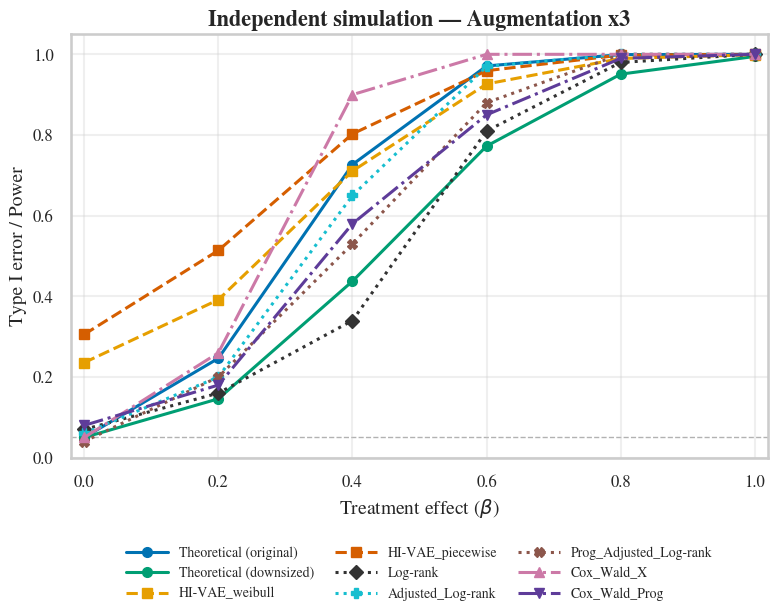


Empirical Type-I error (treatment effect = 0):
                Learner  Type-I error
 Prog_Adjusted_Log-rank      0.040000
             Cox_Wald_X      0.050000
Theoretical (downsized)      0.050086
 Theoretical (original)      0.050172
      Adjusted_Log-rank      0.060000
               Log-rank      0.070000
          Cox_Wald_Prog      0.080000
         HI-VAE_weibull      0.235700
       HI-VAE_piecewise      0.305600


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font="STIXGeneral", context="talk")

# ---------- Configuration ----------
aug_perc = 1 / 3
alpha = 0.05
generators_sel = ["HI-VAE_weibull", "HI-VAE_piecewise"]

current_path = os.getcwd()
parent_path = os.path.dirname(current_path)
folder_path = os.path.join(
    parent_path, "dataset", "Simulations_aug_indep_traincontrol"
)

# ---------- 1. Load simulation results ----------
results = []

for name in sorted(os.listdir(folder_path)):
    if "results_survival_km_distance" in name and name.endswith(".csv"):
        df = pd.read_csv(os.path.join(folder_path, name), index_col=0)
        results.append(df)

if not results:
    raise FileNotFoundError(f"No simulation results found in {folder_path}")

results_control_indep = (
    pd.concat(results, ignore_index=True)
    .sort_values("XP_num")
    .reset_index(drop=True)
)

numeric_cols = [
    "aug_perc", "H0_coef", "H0_coef_univ",
    "D_control", "D_treated"
] + [f"log_pvalue_{name}" for name in generators_sel]

results_control_indep[numeric_cols] = results_control_indep[numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)

# ---------- 2. Select augmentation case ----------
df_res = results_control_indep[
    np.isclose(results_control_indep["aug_perc"], aug_perc)
].copy()

if df_res.empty:
    raise ValueError(f"No results found for aug_perc={aug_perc}")

# ---------- 3. Empirical power of generators ----------
plot_data = []

for name in generators_sel:
    col = f"log_pvalue_{name}"

    power = (
        df_res.assign(reject=df_res[col] > -np.log(alpha))
        .groupby("H0_coef")["reject"]
        .mean()
    )

    for beta, value in power.items():
        plot_data.append({
            "Learner": name,
            "Treatment effect": beta,
            "Power": value
        })

# ---------- 4. Theoretical power ----------
df_theo = df_res.groupby("H0_coef")[
    ["H0_coef_univ", "D_control", "D_treated"]
].mean()

for beta, row in df_theo.iterrows():
    theoretical_cases = {
        "Theoretical (original)": row["D_control"],
        "Theoretical (downsized)": row["D_control"] * aug_perc
    }

    for name, n_control in theoretical_cases.items():
        power = cpower(
            n_control, row["D_treated"],
            row["H0_coef_univ"], alpha
        )

        plot_data.append({
            "Learner": name,
            "Treatment effect": beta,
            "Power": power
        })

# ---------- 5. Add statistical tests ----------
# 'summary' comes from the separate Monte Carlo simulation

statistical_methods = [
    "Log-rank",
    "Adjusted_Log-rank",
    "Prog_Adjusted_Log-rank",
    "Cox_Wald_X",
    "Cox_Wald_Prog"
]

df_adjusted = (
    summary[summary["method"].isin(statistical_methods)]
    .rename(columns={
        "method": "Learner",
        "treatment_effect": "Treatment effect",
        "rejection_rate": "Power"
    })[["Learner", "Treatment effect", "Power"]]
    .copy()
)

missing_methods = set(statistical_methods) - set(df_adjusted["Learner"])

if missing_methods:
    raise ValueError(
        f"Missing methods in summary: {sorted(missing_methods)}. "
        "Rerun the Monte Carlo simulation with all five statistical tests."
    )

df_plot = pd.concat(
    [pd.DataFrame(plot_data), df_adjusted],
    ignore_index=True
)

df_plot["Treatment effect"] = pd.to_numeric(
    df_plot["Treatment effect"], errors="coerce"
)
df_plot["Power"] = pd.to_numeric(
    df_plot["Power"], errors="coerce"
)

df_plot = df_plot.dropna(subset=["Treatment effect", "Power"])

# ---------- 6. Plot styles ----------
styles = {
    "Theoretical (original)": {
        "color": "#0072B2", "ls": "-", "marker": "o"
    },
    "Theoretical (downsized)": {
        "color": "#009E73", "ls": "-", "marker": "o"
    },
    "HI-VAE_weibull": {
        "color": "#E69F00", "ls": "--", "marker": "s"
    },
    "HI-VAE_piecewise": {
        "color": "#D55E00", "ls": "--", "marker": "s"
    },
    "Log-rank": {
        "color": "#333333", "ls": ":", "marker": "D"
    },
    "Adjusted_Log-rank": {
        "color": "#17BECF", "ls": ":", "marker": "P"
    },
    "Prog_Adjusted_Log-rank": {
        "color": "#8C564B", "ls": ":", "marker": "X"
    },
    "Cox_Wald_X": {
        "color": "#CC79A7", "ls": "-.", "marker": "^"
    },
    "Cox_Wald_Prog": {
        "color": "#5E3C99", "ls": "-.", "marker": "v"
    }
}

# ---------- 7. Plot ----------
fig, ax = plt.subplots(figsize=(9, 5.5))

for name, style in styles.items():
    data = df_plot[
        df_plot["Learner"] == name
    ].sort_values("Treatment effect")

    if data.empty:
        continue

    ax.plot(
        data["Treatment effect"],
        data["Power"],
        label=name,
        color=style["color"],
        linestyle=style["ls"],
        marker=style["marker"],
        linewidth=2.2,
        markersize=7
    )

# ---------- 8. Axes and reference ----------
ax.set_title(
    "Independent simulation — Augmentation x3",
    fontsize=16,
    fontweight="semibold"
)
ax.set_xlabel(r"Treatment effect ($\beta$)", fontsize=14)
ax.set_ylabel("Type I error / Power", fontsize=14)

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(0, 1.05)
ax.set_xticks(np.arange(0, 1.1, 0.2))
ax.set_yticks(np.arange(0, 1.1, 0.2))
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)

# Nominal Type-I error level
ax.axhline(
    alpha,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.6,
    zorder=0
)

# ---------- 9. Legend ----------
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    fontsize=10,
    frameon=False,
    columnspacing=1.5,
    handlelength=3
)

# ---------- 10. Save ----------
# savepath = os.path.join(
#     parent_path, "figures", "simu_indep_aug3_comparison.pdf"
# )
# os.makedirs(os.path.dirname(savepath), exist_ok=True)
# fig.savefig(savepath, bbox_inches="tight", dpi=300)

plt.show()

# ---------- 11. Type-I error comparison ----------
type1_error = (
    df_plot[np.isclose(df_plot["Treatment effect"], 0.0)]
    [["Learner", "Power"]]
    .rename(columns={"Power": "Type-I error"})
    .sort_values("Type-I error")
)

print("\nEmpirical Type-I error (treatment effect = 0):")
print(type1_error.to_string(index=False))